# 05 · Clasificador de envases (variante A)

**Problema.** El detector YOLO de una clase (`producto`) encuentra cada envase de la foto y lo
recorta. Este notebook entrena la red que mira **cada recorte** y dice cuál de las **9 clases**
es (marca + formato), en el orden de `config/clases.json`:

`coca_botella, coca_lata, fanta_botella, fanta_lata, sprite_botella, sprite_lata, pepsi_botella, pepsi_lata, 7up_lata`

Es la **práctica 01 (perros y gatos) generalizada**: mismas ideas (CNN, Dropout, aumento de
datos, TensorBoard, comparar modelos por validación) pero con 9 clases en vez de 2, imágenes en
color y una tercera técnica nueva, **transfer learning**.

| práctica 01 | este notebook |
|---|---|
| 100x100, **escala de grises** | 128x128 (CNN) / 160x160 (MobileNetV2), **RGB** + *letterbox* |
| `/255` antes de entrenar | normalización **dentro** del modelo (`Rescaling`) |
| `ImageDataGenerator` | capas `Random*` de Keras **dentro** del modelo, sin volteos |
| 1 neurona `sigmoid` + `binary_crossentropy` | 9 neuronas `softmax` + `sparse_categorical_crossentropy` |
| `modeloCNN`, `modeloCNN2_AD` | `cnn`, `cnn_ad` (mismas arquitecturas) + `mobilenet` |
| `tfds.load('cats_vs_dogs')` | `datos/recortes/{train,val,test}/<clase>/*.jpg` (agente Datos) |

La lógica vive en `src/vision/clasificador_modelos.py` (preprocesamiento y arquitecturas),
`scripts/clasificador_entrenar.py` (entrenamiento, métricas, comparación) y
`src/vision/clasificador.py` (inferencia). Este notebook los llama y muestra los resultados.

In [1]:
import os, sys
from pathlib import Path
print('Python:', sys.executable)        # debe ser ...\envs\inventariovision\python.exe

# REPO = checkout con el código (puede ser un worktree). MAIN = carpeta principal con datos/modelos/logs.
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
MAIN = REPO.parents[2] if REPO.parent.name == 'worktrees' and REPO.parent.parent.name == '.claude' else REPO
os.environ.setdefault('INVENTARIO_DATOS', str(MAIN / 'datos'))
os.environ.setdefault('INVENTARIO_MODELOS', str(MAIN / 'modelos'))
os.environ.setdefault('INVENTARIO_LOGS', str(MAIN / 'logs'))
sys.path.insert(0, str(REPO))
# %tensorboard lanza el tensorboard.exe que encuentra primero en el PATH (el de base): forzamos el del entorno.
os.environ['TENSORBOARD_BINARY'] = str(Path(sys.executable).parent / 'Scripts' / 'tensorboard.exe')

from src import config
DIR_RECORTES = config.DIR_DATOS / 'recortes'
DIR_CLF = config.DIR_MODELOS / 'clasificador'
DIR_LOGS_CLF = config.DIR_LOGS / 'clasificador'
SCRIPT = REPO / 'scripts' / 'clasificador_entrenar.py'
print('REPO     :', REPO)
print('Recortes :', DIR_RECORTES)
print('Modelos  :', DIR_CLF)
print('Logs     :', DIR_LOGS_CLF)

Python: C:\Users\limber\anaconda3\envs\inventariovision\python.exe
REPO     : C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\.claude\worktrees\agent-a634346fab9d01d36
Recortes : C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\datos\recortes
Modelos  : C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\modelos\clasificador
Logs     : C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\logs\clasificador


In [2]:
# TensorFlow comparte la CPU con otros procesos: lo limitamos a 4 hilos ANTES de usarlo.
import tensorflow as tf
try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    print('TensorFlow ya estaba inicializado: reiniciá el kernel si querés limitar los hilos.')
import keras, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image as IImage, Markdown
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
print('TensorFlow', tf.__version__, '· Keras', keras.__version__, '· GPU:', tf.config.list_physical_devices('GPU') or 'no (CPU)')
CLASES = config.nombres_clases()

TensorFlow 2.20.0 · Keras 3.15.1 · GPU: no (CPU)


## 1. Los datos

Los recortes los genera el agente Datos a partir de los datasets públicos fusionados: cada caja
anotada se recorta de su foto y se guarda en `datos/recortes/<split>/<clase>/`. La división
train/val/test es **por foto original** (las copias aumentadas de Roboflow de una misma foto
quedan en el mismo split), para que validación y test midan generalización y no memoria.

Descartados por el agente Datos: 72


,train,val,test
coca_botella,1070,150,141
coca_lata,913,97,110
fanta_botella,992,144,115
fanta_lata,30,4,4
sprite_botella,1047,131,137
sprite_lata,180,27,24
pepsi_botella,264,38,29
pepsi_lata,218,31,34
7up_lata,244,39,36
TOTAL,4958,661,630


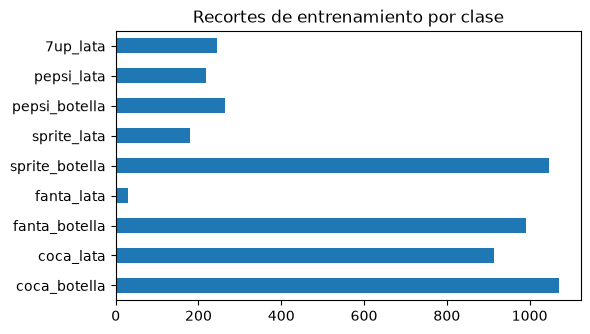

In [3]:
import subprocess
idx_path = DIR_RECORTES / 'indice_recortes.csv'
if idx_path.exists():
    idx = pd.read_csv(idx_path)
    if 'motivo_descarte' in idx:
        print('Descartados por el agente Datos:', idx['motivo_descarte'].notna().sum())
        idx = idx[idx['motivo_descarte'].isna()]
conteo = pd.DataFrame({s: {c: len(list((DIR_RECORTES / s / c).glob('*.jpg'))) for c in CLASES}
                       for s in ('train', 'val', 'test')})
conteo.loc['TOTAL'] = conteo.sum()
display(conteo)
conteo.drop('TOTAL')['train'].plot.barh(title='Recortes de entrenamiento por clase', figsize=(6, 3.5)); plt.show()

**Desbalance.** Si una clase tiene muchos menos ejemplos (por ejemplo `fanta_lata`), la red
puede aprender a "no predecirla nunca" y aun así tener buen accuracy global. Por eso se usa
`class_weight`: el error en una clase rara pesa más en la pérdida (peso ∝ 1/frecuencia, topeado
en 10 para no desestabilizar el entrenamiento). Y por eso se mira **precisión y recall por clase**,
no solo el accuracy.

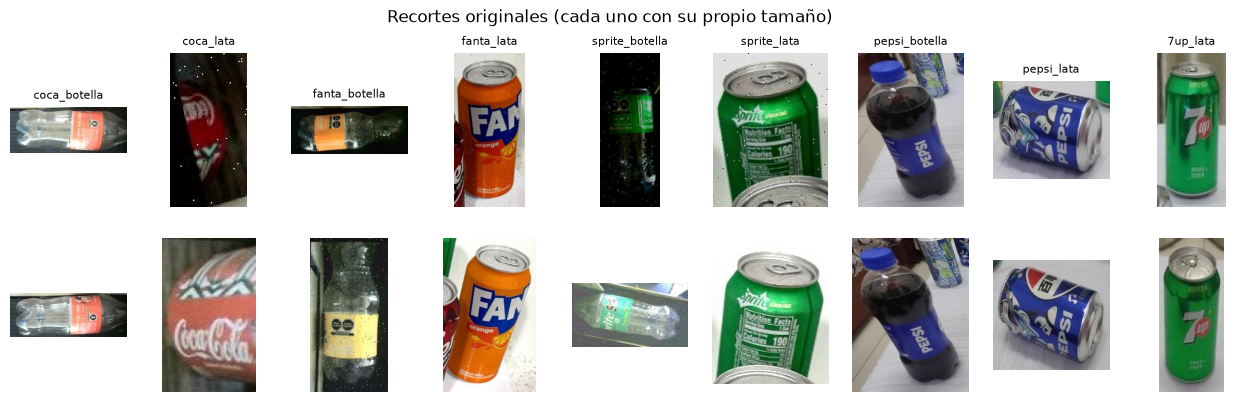

In [4]:
from src.vision.clasificador_modelos import cargar_imagen, letterbox
fig, ejes = plt.subplots(2, 9, figsize=(16, 4.4))
for j, c in enumerate(CLASES):
    rutas = sorted((DIR_RECORTES / 'train' / c).glob('*.jpg'))[:2]
    for i in range(2):
        ax = ejes[i, j]; ax.axis('off')
        if i < len(rutas):
            ax.imshow(cargar_imagen(rutas[i]))
        if i == 0: ax.set_title(c, fontsize=8)
plt.suptitle('Recortes originales (cada uno con su propio tamaño)'); plt.show()

## 2. Preprocesamiento común: RGB + *letterbox*

1. **RGB, no gris.** En la práctica 01 el gris alcanzaba (perro y gato no se distinguen por
   color). Acá el color es la pista principal: Coca roja, Fanta naranja, Sprite y 7up verdes,
   Pepsi azul. En gris, Coca y Fanta se parecen mucho.
2. **Letterbox, no estirar.** Los recortes tienen proporciones muy distintas: una botella es alta
   y flaca, una lata es más ancha. Si se los estira a un cuadrado, la botella queda "gorda" y se
   parece a una lata, justo la diferencia que el modelo tiene que aprender. El *letterbox* escala
   el lado mayor al tamaño final y rellena el resto con gris (128), sin deformar.
3. **Tamaño.** 128 px para las CNN desde cero (100 px, el de la práctica, deja ilegibles los
   logos de los recortes chicos; más grande multiplica el costo, que crece con el cuadrado del
   lado). 160 px para MobileNetV2: es uno de los tamaños con pesos de ImageNet, cuesta la mitad
   que 224 (160² / 224² ≈ 0,51) y alcanza para logos grandes y de colores muy distintos.
4. **El mismo código en entrenamiento y en inferencia** (`letterbox()`), y la normalización
   **dentro** del modelo. El `.keras` guardado recibe píxeles 0-255 tal cual: el pipeline no
   necesita saber si ganó la CNN (`/255`) o MobileNetV2 (`[-1, 1]`).

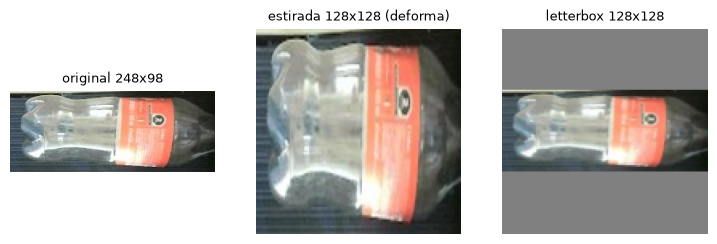

In [5]:
from PIL import Image
ruta = sorted((DIR_RECORTES / 'train' / 'coca_botella').glob('*.jpg'))[0]
orig = cargar_imagen(ruta)
estirada = np.asarray(Image.fromarray(orig).resize((128, 128)))
fig, ax = plt.subplots(1, 3, figsize=(9, 3.4))
for a, im, t in zip(ax, [orig, estirada, letterbox(orig, 128)],
                    [f'original {orig.shape[1]}x{orig.shape[0]}', 'estirada 128x128 (deforma)', 'letterbox 128x128']):
    a.imshow(im); a.set_title(t, fontsize=9); a.axis('off')
plt.show()

## 3. Aumento de datos con capas Keras

En la práctica 01 se usó `ImageDataGenerator` (deprecado). Acá el aumento son **capas** al
comienzo del modelo: solo actúan al entrenar (`training=True`) y en inferencia son la identidad,
así que viajan dentro del `.keras` sin molestar.

| capa | valor | por qué |
|---|---|---|
| `RandomRotation(0.028)` | ±10° (0,028·360°) | la foto del estante casi siempre está derecha; 30° (práctica 01) es irreal |
| `RandomZoom(0.15)` | ±15 % | el detector no recorta siempre igual de ajustado |
| `RandomTranslation(0.08)` | ±8 % | idem, cajas un poco corridas |
| `RandomBrightness(0.2)` | ±20 % | iluminación del local |
| `RandomContrast(0.2)` | ±20 % | cámaras y luces distintas |
| volteo vertical | **no** | una botella cabeza abajo no existe en un estante |
| volteo horizontal | **no** | invierte el texto y el logo: "Coca-Cola" en espejo no existe, y las marcas se distinguen justamente por logo y tipografía (Sprite y 7up son ambas verdes). En perros y gatos sí servía: un perro en espejo sigue siendo un perro. |
| cambio de tono (*hue*) | **no** | cambiaría el color, que es la pista principal |

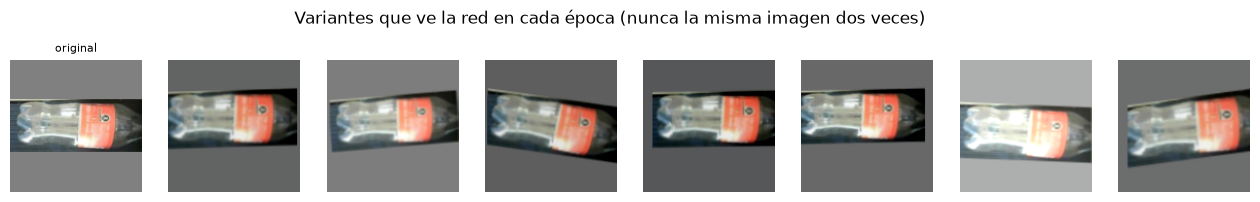

In [6]:
from src.vision.clasificador_modelos import capas_aumento
aum = capas_aumento()
x = letterbox(orig, 128)[None].astype('float32')
fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
ax[0].imshow(x[0].astype('uint8')); ax[0].set_title('original', fontsize=8)
for a in ax[1:]:
    a.imshow(np.clip(aum(x, training=True)[0].numpy(), 0, 255).astype('uint8'))
for a in ax: a.axis('off')
plt.suptitle('Variantes que ve la red en cada época (nunca la misma imagen dos veces)'); plt.show()

## 4. De sigmoid a softmax

En la práctica 01 había **2 clases** y una sola neurona de salida con **sigmoid**:
$p = \sigma(z) = \frac{1}{1+e^{-z}}$ es la probabilidad de "perro" y $1-p$ la de "gato"; umbral 0,5.
La pérdida era `binary_crossentropy`: $-[y\log p + (1-y)\log(1-p)]$.

Con **9 clases** excluyentes (un recorte es exactamente una de ellas) se usan **9 neuronas** con
**softmax**: $p_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$. Cada $p_i$ está entre 0 y 1 y **suman 1**: es
una distribución de probabilidad sobre las clases. La predicción es la clase con mayor $p_i$ y esa
$p_i$ es la **confianza**.

¿Por qué no 9 sigmoids? Cada sigmoid es independiente: podrían dar 0,9 para Coca **y** 0,9 para
Fanta a la vez (sirve para multi-etiqueta, no acá). Softmax obliga a "repartir" la probabilidad.

La pérdida es la entropía cruzada categórica: $-\log p_{y}$ (menos el logaritmo de la
probabilidad que se le dio a la clase correcta). La variante **`sparse_`** recibe la etiqueta
como entero (0..8) en vez de un vector one-hot `[0,0,1,0,…]`: es lo mismo, con menos memoria.

**Umbral → "desconocido".** Si la confianza máxima es menor que `UMBRAL_CONF` (0,5 por defecto),
el clasificador devuelve `"desconocido"`: un producto que no es de las 9 clases (otra marca) o un
recorte malo. Mejor admitir la duda que descontar stock del producto equivocado.

In [7]:
z = np.array([2.0, 1.0, 0.1, -1.0, 0.5, 0.0, -0.5, -2.0, 0.3])    # salidas "crudas" (logits) de la última capa
p = np.exp(z) / np.exp(z).sum()
print('softmax :', np.round(p, 3), ' suma =', p.sum().round(3))
print('sigmoid :', np.round(1 / (1 + np.exp(-z)), 3), ' suma =', (1 / (1 + np.exp(-z))).sum().round(3), '(no es una distribución)')
print(f'predicción: {CLASES[p.argmax()]} con confianza {p.max():.2f} → '
      f'{"aceptada" if p.max() >= config.UMBRAL_CONF else "desconocido"} (umbral {config.UMBRAL_CONF})')
print('pérdida si la clase real es la 0:', round(-np.log(p[0]), 3), '· si es la 7:', round(-np.log(p[7]), 3))

softmax : [0.453 0.167 0.068 0.023 0.101 0.061 0.037 0.008 0.083]  suma = 1.0
sigmoid : [0.881 0.731 0.525 0.269 0.622 0.5   0.378 0.119 0.574]  suma = 4.599 (no es una distribución)
predicción: coca_botella con confianza 0.45 → desconocido (umbral 0.5)
pérdida si la clase real es la 0: 0.792 · si es la 7: 4.792


## 5. Los tres modelos

**(a) `cnn` = `modeloCNN`** de la práctica: Conv32 → MaxPool → Conv64 → MaxPool → Conv128 →
MaxPool → Flatten → Dense100 → **Dense9 softmax**. Sin regularización: se espera que
sobreajuste (train ≫ val), como en perros y gatos.

**(b) `cnn_ad` = `modeloCNN2_AD`**: la misma red + aumento de datos + `Dropout(0.5)` antes de
Flatten + Dense250. Dropout apaga al azar la mitad de las activaciones en cada paso, así la red
no puede depender de unas pocas neuronas; el aumento hace que nunca vea dos veces la misma imagen.
Las dos cosas atacan el sobreajuste.

**(c) `mobilenet` = transfer learning.** Una red desde cero tiene que aprender **todo** (bordes,
texturas, formas, letras) con solo unos miles de recortes. *Transfer learning* reutiliza una red
ya entrenada con 1,2 millones de fotos de ImageNet (**MobileNetV2**, liviana, pensada para
celulares): sus capas convolucionales ya saben extraer rasgos visuales generales. Se le quita la
cabeza original (1000 clases de ImageNet) y se le pone una nueva: `GlobalAveragePooling →
Dropout(0.3) → Dense9 softmax`. Dos fases:

1. **Base congelada** (`trainable=False`), lr 1e-3: solo se entrena la cabeza (≈ 11 mil
   parámetros de 2,3 millones). Rápido y sin riesgo de arruinar lo aprendido.
2. **Fine-tuning**: se descongelan las últimas 30 capas de la base y se sigue entrenando con un
   lr **100 veces menor** (1e-5), para ajustar los rasgos de alto nivel a logos de bebidas sin
   "olvidar" lo de ImageNet. Las capas **BatchNormalization se dejan congeladas** (y la base se
   llama con `training=False`): con lotes de 32 sus medias y varianzas se arruinarían.

En los tres: `optimizer=Adam`, `batch_size=32`, `EarlyStopping` (corta cuando `val_loss` deja de
mejorar y restaura la mejor época), `ModelCheckpoint` (guarda la mejor época en disco, por si se
corta), `ReduceLROnPlateau` y **TensorBoard** en `logs/clasificador/<modelo>_<fecha>`.

In [8]:
from src.vision import clasificador_modelos as cm
for nombre in cm.MODELOS:
    m = cm.construir(nombre, len(CLASES), pesos=None)
    entrenables = sum(int(np.prod(w.shape)) for w in m.trainable_weights)
    print(f'{nombre:10s} entrada {m.input_shape[1]}x{m.input_shape[2]}x3 · {m.count_params():>10,} parámetros · {entrenables:>10,} entrenables')
cm.construir('cnn_ad', len(CLASES)).summary()
keras.backend.clear_session()

cnn        entrada 128x128x3 ·  2,603,057 parámetros ·  2,603,057 entrenables


cnn_ad     entrada 128x128x3 ·  6,367,757 parámetros ·  6,367,757 entrenables


mobilenet  entrada 160x160x3 ·  2,269,513 parámetros ·     11,529 entrenables


Model: "cnn_ad"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)                  │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ aumento (Sequential)                 │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ escala_0_1 (Rescaling)               │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1 (Conv2D)                       │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool1 (MaxPooling2D)                 │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2 (Conv2D)                       │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool2 (MaxPooling2D)                 │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3 (Conv2D)                       │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ pool3 (MaxPooling2D)                 │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ aplanar (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ densa (Dense)                        │ (None, 250)                 │       6,272,250 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ clases (Dense)                       │ (None, 9)                   │           2,259 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,367,757 (24.29 MB)

 Trainable params: 6,367,757 (24.29 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Probar barato antes de lo caro

Igual que en la práctica 01 (`epochs=1` antes de lanzar 100): `--prueba` entrena cada modelo
**2 épocas con 16 recortes por clase** (la 1.ª incluye compilar y leer los JPEG; la 2.ª mide la
velocidad real) y extrapola cuánto tardaría el entrenamiento completo **en esta PC**. Guarda en
`modelos/clasificador/prueba/` y no toca el modelo final. Tarda ~1-2 minutos.

In [9]:
def correr(*args):
    # Corre scripts/clasificador_entrenar.py en un subproceso y muestra la salida en vivo.
    cmd = [sys.executable, '-u', str(SCRIPT), *map(str, args)]
    env = {**os.environ, 'PYTHONIOENCODING': 'utf-8'}
    with subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                          encoding='utf-8', errors='replace', env=env) as p:
        for linea in p.stdout:
            if 'oneDNN' not in linea and 'UserWarning' not in linea and 'data_adapter' not in linea:
                print(linea, end='')
    if p.returncode: raise RuntimeError(f'falló ({p.returncode})')

PROBAR = True
if PROBAR:
    correr('--modelo', 'todos', '--prueba')

Recortes: C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\datos\recortes  (indice_recortes.csv presente)



=== cnn  (entrada 128x128) ===
  train    144  coca_botella=16  coca_lata=16  fanta_botella=16  fanta_lata=16  sprite_botella=16  sprite_lata=16  pepsi_botella=16  pepsi_lata=16  7up_lata=16
  val      132  coca_botella=16  coca_lata=16  fanta_botella=16  fanta_lata=4  sprite_botella=16  sprite_lata=16  pepsi_botella=16  pepsi_lata=16  7up_lata=16
  test     132  coca_botella=16  coca_lata=16  fanta_botella=16  fanta_lata=4  sprite_botella=16  sprite_lata=16  pepsi_botella=16  pepsi_lata=16  7up_lata=16


  2,603,057 parámetros (2,603,057 entrenables)


Epoch 1/2


5/5 - 21s - 4s/step - accuracy: 0.1458 - loss: 2.2388 - val_accuracy: 0.1515 - val_loss: 2.0982 - learning_rate: 0.0010
Epoch 2/2


5/5 - 5s - 1s/step - accuracy: 0.2222 - loss: 1.9378 - val_accuracy: 0.2955 - val_loss: 1.7822 - learning_rate: 0.0010


... (12 outputs left out)

5/5 - 16s - 3s/step - accuracy: 0.3194 - loss: 1.8445 - val_accuracy: 0.3258 - val_loss: 1.8594 - learning_rate: 1.0000e-05
Epoch 4/4


5/5 - 3s - 644ms/step - accuracy: 0.3611 - loss: 1.7025 - val_accuracy: 0.4091 - val_loss: 1.7439 - learning_rate: 1.0000e-05



  mobilenet: 0.6 min, 4 épocas
  val   accuracy 0.409  loss 1.744  macro-F1 0.413  botella↔lata 14  sprite↔7up 8
  test  accuracy 0.394  loss 1.681  macro-F1 0.380  botella↔lata 14  sprite↔7up 8
  Velocidad (época 2, ya en caché): 11.3 s cada 1000 imágenes (train+val)
  Estimación con 5619 imágenes (train+val): ~1.1 min/época × 15 épocas = ~16 min como máximo (EarlyStopping suele cortar antes)
  Fine-tuning: ~1.1 min/época × 10 = ~11 min
  (la 1.ª época real tarda más: decodifica todos los JPEG antes de cachearlos)



Comparación:
| modelo | entrada | parámetros | épocas | min | val acc | val loss | test acc | test loss | test F1 macro | bot↔lata (test) | sprite↔7up (test) | umbral sug. | n train | prueba |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| cnn | 128px | 2.603.057 | 2 | 0.560 | 0.295 | 1.782 | 0.265 | 1.757 | 0.215 | 21 | 12 | 0.750 | 144 | sí |
| cnn_ad | 128px | 6.367.757 | 2 | 0.210 | 0.167 | 2.107 | 0.174 | 2.113 | 0.107 | 24 | 0 | 0.500 | 144 | sí |
| mobilenet | 160px | 2.269.513 | 4 | 0.640 | 0.409 | 1.744 | 0.394 | 1.681 | 0.380 | 14 | 8 | 0.600 | 144 | sí |

Elegido: mobilenet → C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\modelos\clasificador\prueba\clasificador.keras (umbral sugerido 0.6)
TensorBoard: tensorboard --logdir "C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\logs\clasificador\prueba"


## 7. Entrenamiento completo

Elegí qué entrenar **acá** (CPU, 4 hilos) y qué en **Colab** (GPU, ver
`notebooks/05_clasificador_colab.ipynb` y `docs/clasificador.md`). Con la estimación de la celda
anterior: si un modelo pasa de ~1 hora, conviene Colab. Los entrenamientos largos, con la PC
enchufada (el script evita que Windows se suspenda mientras corre).

Cada modelo guarda `modelos/clasificador/<modelo>.keras` y sus métricas; al final se arma la
comparación y el mejor por `val_accuracy` se copia a `clasificador.keras` (el que usa el pipeline).

In [10]:
ENTRENAR = {'cnn': False, 'cnn_ad': False, 'mobilenet': False}   # poner True lo que se quiera entrenar acá
for nombre, si in ENTRENAR.items():
    if si:
        correr('--modelo', nombre, '--actualizar-doc')
if not any(ENTRENAR.values()):
    print('No se entrena nada (todo en False). Se muestran los resultados que haya en', DIR_CLF)

No se entrena nada (todo en False). Se muestran los resultados que haya en C:\Users\limber\Documents\Semestres\2-2026\Preparacion Decisiones\IA\control_inventario\modelos\clasificador


## 8. TensorBoard

Curvas por época de *accuracy* y *loss* de entrenamiento vs. validación. Igual que en la
práctica: lo que importa es la **validación**. Si `accuracy` sigue subiendo y `val_accuracy` se
estanca (o `val_loss` sube), el modelo está memorizando (sobreajuste).

Alternativa fuera del notebook: `tensorboard --logdir logs/clasificador` en Anaconda Prompt con
el entorno activado y abrir http://localhost:6006.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir "{DIR_LOGS_CLF}"

## 9. Comparación de modelos

La tabla sale de `modelos/clasificador/comparacion.csv` (la arma el script con todos los
modelos entrenados). Columnas `bot↔lata` y `sprite↔7up`: cuántos recortes de test se confundieron
entre botella y lata **de la misma marca**, y entre Sprite y 7up (las dos verdes). Son los errores
más caros para el inventario: el producto existe pero se descuenta el equivocado.

In [12]:
dir_res = DIR_CLF if (DIR_CLF / 'comparacion.csv').exists() else DIR_CLF / 'prueba'
if (dir_res / 'comparacion.csv').exists():
    if dir_res.name == 'prueba':
        display(Markdown('**Atención: son resultados de la corrida de PRUEBA (2 épocas, 16 recortes por clase), no del entrenamiento real.**'))
    comp = pd.read_csv(dir_res / 'comparacion.csv')
    display(comp)
else:
    print('Todavía no hay modelos entrenados en', DIR_CLF)

,modelo,tamano,parametros,epocas,minutos,val_accuracy,val_loss,val_macro_f1,test_accuracy,test_loss,test_macro_f1,test_botella_lata,test_sprite_7up,umbral_sugerido,n_train,prueba,fecha
0,mobilenet,160,2269513,25,37.57,0.9713,0.1058,0.9686,0.9667,0.1571,0.9441,6,1,0.5,4958,False,2026-10-15T23:24:34


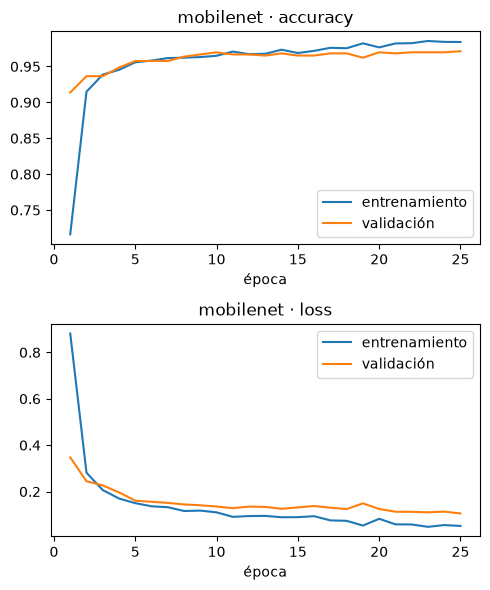

In [13]:
# Curvas de entrenamiento vs. validación (desde <modelo>_historial.csv)
hists = {m: pd.read_csv(dir_res / f'{m}_historial.csv') for m in cm.MODELOS if (dir_res / f'{m}_historial.csv').exists()}
if hists:
    fig, ax = plt.subplots(2, len(hists), figsize=(5 * len(hists), 6), squeeze=False)
    for j, (m, h) in enumerate(hists.items()):
        for i, met in enumerate(['accuracy', 'loss']):
            ax[i, j].plot(h['epoch'] + 1, h[met], label='entrenamiento')
            ax[i, j].plot(h['epoch'] + 1, h[f'val_{met}'], label='validación')
            ax[i, j].set_title(f'{m} · {met}'); ax[i, j].set_xlabel('época'); ax[i, j].legend()
    plt.tight_layout(); plt.show()

## 10. El modelo elegido: matriz de confusión y métricas por clase

- **Precisión** de una clase: de los recortes que el modelo llamó "coca_lata", ¿qué parte lo era?
- **Recall**: de las coca_lata reales, ¿qué parte encontró?
- **Matriz de confusión**: fila = clase real, columna = predicha. La diagonal son aciertos; fuera
  de ella, qué se confunde con qué.

Elegido: mobilenet (160 px) · umbral sugerido 0.5


**val** · accuracy 0.971 · loss 0.106

,precision,recall,f1-score,support
coca_botella,0.973,0.960,0.966,150.0
coca_lata,0.990,0.990,0.990,97.0
fanta_botella,0.972,0.972,0.972,144.0
fanta_lata,1.000,1.000,1.000,4.0
sprite_botella,0.963,1.000,0.981,131.0
sprite_lata,0.963,0.963,0.963,27.0
pepsi_botella,0.946,0.921,0.933,38.0
pepsi_lata,0.967,0.935,0.951,31.0
7up_lata,0.974,0.949,0.961,39.0


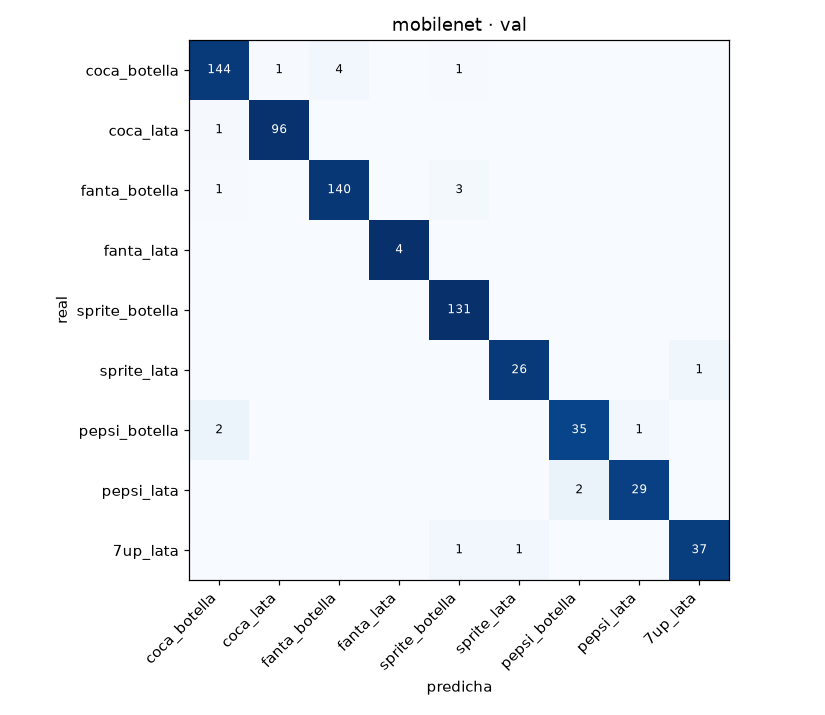

**test** · accuracy 0.967 · loss 0.157

,precision,recall,f1-score,support
coca_botella,0.965,0.965,0.965,141.0
coca_lata,1.000,0.964,0.981,110.0
fanta_botella,0.973,0.957,0.965,115.0
fanta_lata,0.667,1.000,0.800,4.0
sprite_botella,0.978,0.971,0.974,137.0
sprite_lata,0.885,0.958,0.920,24.0
pepsi_botella,0.879,1.000,0.935,29.0
pepsi_lata,1.000,0.941,0.970,34.0
7up_lata,0.973,1.000,0.986,36.0


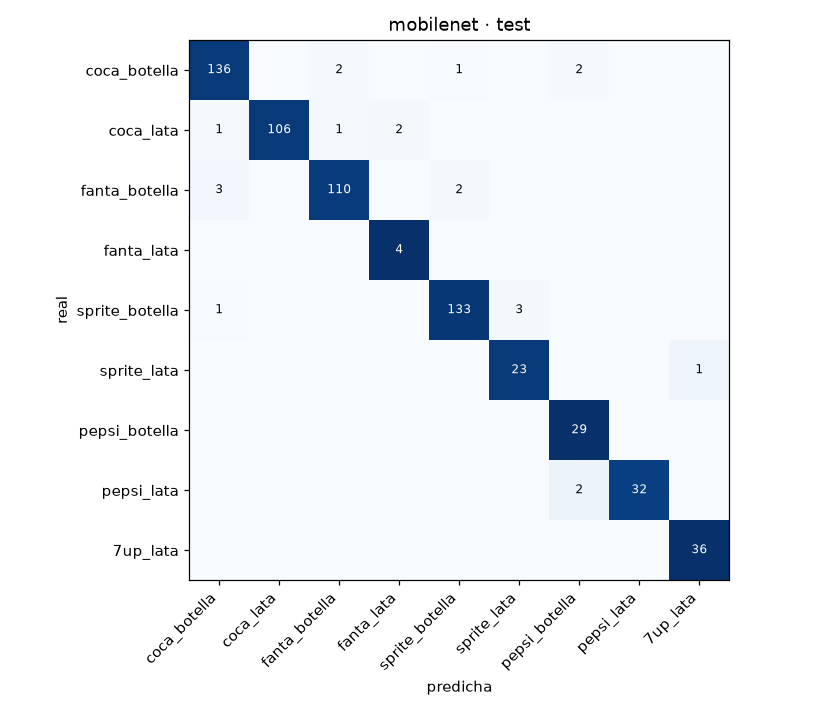

,de,a,n,tasa
0,coca_botella,coca_lata,0,0.000000
1,coca_lata,coca_botella,1,0.009091
2,fanta_botella,fanta_lata,0,0.000000
3,fanta_lata,fanta_botella,0,0.000000
4,pepsi_botella,pepsi_lata,0,0.000000
5,pepsi_lata,pepsi_botella,2,0.058824
6,sprite_botella,sprite_lata,3,0.021898
7,sprite_lata,sprite_botella,0,0.000000
8,sprite_lata,7up_lata,1,0.041667
9,7up_lata,sprite_lata,0,0.000000


In [14]:
import json
if (dir_res / 'metricas.json').exists():
    res = json.loads((dir_res / 'metricas.json').read_text(encoding='utf-8'))
    elegido = res['modelo']
    met = json.loads((dir_res / f'{elegido}_metricas.json').read_text(encoding='utf-8'))
    print(f"Elegido: {elegido} ({res['tamano_entrada']} px) · umbral sugerido {res['umbral_sugerido']}")
    for split in ('val', 'test'):
        if met.get(split, {}).get('n'):
            rep = pd.DataFrame(met[split]['reporte']).T.loc[CLASES, ['precision', 'recall', 'f1-score', 'support']]
            display(Markdown(f"**{split}** · accuracy {met[split]['accuracy']:.3f} · loss {met[split]['loss']:.3f}"))
            display(rep.round(3))
            display(IImage(filename=str(dir_res / f'matriz_{elegido}_{split}.png'), width=560))
    cc = met['test']['confusiones_clave'] if met.get('test', {}).get('n') else met['val']['confusiones_clave']
    display(pd.DataFrame(cc['botella_lata'] + cc['sprite_7up']))

### Umbral de confianza

Al subir el umbral se aceptan menos recortes (más "desconocido") pero los aceptados son más
confiables. El script sugiere el menor umbral ≥ 0,5 cuyo accuracy sobre lo aceptado llega al
95 % (en validación); queda en `metricas.json` → `umbral_sugerido`.

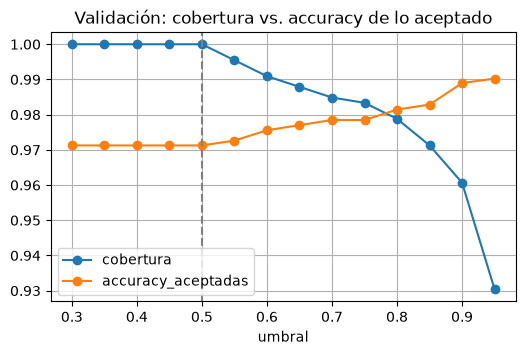

In [15]:
if (dir_res / 'metricas.json').exists():
    b = pd.DataFrame(met['val']['barrido_umbral'])
    ax = b.plot(x='umbral', y=['cobertura', 'accuracy_aceptadas'], marker='o', figsize=(6, 3.5), grid=True)
    ax.axvline(res['umbral_sugerido'], ls='--', c='gray'); ax.set_title('Validación: cobertura vs. accuracy de lo aceptado')
    plt.show()

## 11. Uso desde el pipeline

`src/vision/clasificador.py` implementa el contrato `clasificar(recortes) -> list[tuple[str, float]]`:
recibe recortes RGB uint8 de cualquier tamaño, les aplica el mismo letterbox, clasifica en lote y
devuelve `("desconocido", conf)` si `conf < umbral`. Antes de usar el modelo verifica que su
`clases.json` tenga el mismo orden que `config/clases.json`.

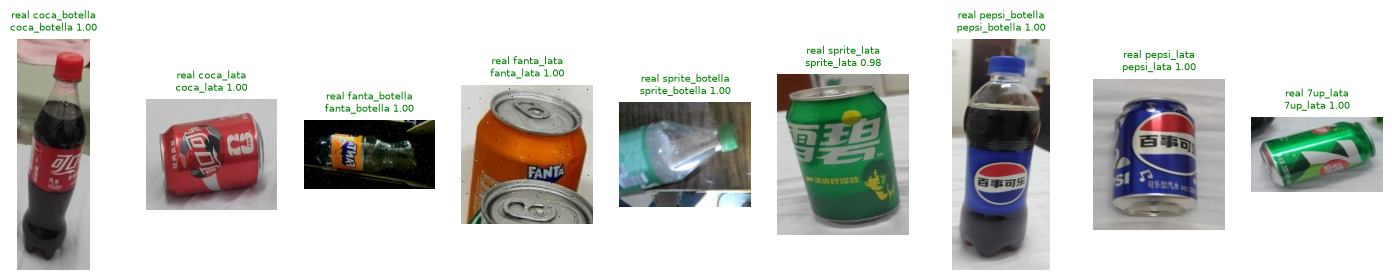

In [16]:
from src.vision.clasificador import Clasificador
ruta_modelo = dir_res / 'clasificador.keras'
if ruta_modelo.exists():
    clf = Clasificador(ruta_modelo)
    rng = np.random.default_rng(0)
    muestras = [(c, p) for c in CLASES for p in rng.permutation(sorted((DIR_RECORTES / 'test' / c).glob('*.jpg')))[:1]]
    preds = clf.clasificar([cargar_imagen(p) for _, p in muestras])
    fig, ax = plt.subplots(1, len(muestras), figsize=(18, 3))
    for a, (real, p), (pred, conf) in zip(ax, muestras, preds):
        a.imshow(cargar_imagen(p)); a.axis('off')
        a.set_title(f'real {real}\n{pred} {conf:.2f}', fontsize=7, color='green' if pred == real else 'red')
    plt.show()

## 12. Conclusiones (completar con los números de la tabla)

- **CNN sin regularización (`cnn`)**: ¿sobreajusta? Comparar accuracy de entrenamiento vs. validación en TensorBoard.
- **CNN + Dropout + aumento (`cnn_ad`)**: ¿se achica la brecha? ¿mejora la validación?
- **Transfer learning (`mobilenet`)**: ¿cuánto mejora con muchos menos parámetros entrenables? ¿qué aportó el fine-tuning (épocas después del corte en las curvas)?
- **Errores típicos**: botella vs. lata de la misma marca y Sprite vs. 7up.
- **Clase con pocos datos** (ver la tabla de la sección 1): su recall, y si `class_weight` alcanzó.